In [1]:
import pandas as pd
import networkx as nx
import os

LPSIM_DIR = os.environ["LPSim"]
city = "SFO"
# Load data
nodes = pd.read_csv(os.path.join(LPSIM_DIR,"LivingCity","berkeley_2018",city,'nodes.csv'))
edges = pd.read_csv(os.path.join(LPSIM_DIR,"LivingCity","berkeley_2018",city,'edges.csv'))

# Create a directed graph (change to nx.Graph() if undirected)
G = nx.DiGraph()

# Add nodes with attributes (optional, here just index)
for _, row in nodes.iterrows():
    G.add_node(row['index'], osmid=row['osmid'], x=row['x'], y=row['y'], ref=row['ref'], highway=row['highway'])

# Add edges with features
for _, row in edges.iterrows():
    G.add_edge(
        row['u'], row['v'],
        length=row['length'],
        speed_mph=row['speed_mph'],
        lanes=row['lanes'],
        osmid_u=row['osmid_u'],
        osmid_v=row['osmid_v']
    )

# Count connected components
# For directed graphs, use strongly or weakly connected components
num_weakly_connected = nx.number_weakly_connected_components(G)
num_strongly_connected = nx.number_strongly_connected_components(G)

print(f"Number of weakly connected components: {num_weakly_connected}")
print(f"Number of strongly connected components: {num_strongly_connected}")



Number of weakly connected components: 1
Number of strongly connected components: 1


In [2]:
import polars as pl
UCI = 0.564
df_OD = pl.read_csv(os.path.join(LPSIM_DIR,"LivingCity","berkeley_2018","new_full_network",f"{city}_oddemand_7_8_R_20_UCI_{UCI}_realization_0.csv"))

In [3]:
df_OD

SAMPN,PERNO,origin_osmid,destination_osmid,dep_time,origin,destination
i64,i64,i64,i64,f64,i64,i64
0,0,65333347,65354417,0.0,25529,25690
1,1,65296818,65363153,0.0,25049,25733
2,2,349900691,2505145364,0.0,31585,28983
3,3,347279843,6433447273,0.0,31571,30075
4,4,5347267393,6991050175,720.0,32095,30304
…,…,…,…,…,…,…
7198944,7198944,3957246779,2932962483,86104.918033,22521,22453
7198945,7198945,241864892,1087030010,86163.934426,20808,22023
7198946,7198946,6862263616,241864891,86222.95082,22969,20807


In [4]:
import json
with open("/home/alberto/LPSim/traffic_phase_transition/data/carto/SFO/grid/0.02/grid2origindest.json","r") as f:
    grid2OD = json.load(f)
grid2OD

{'9707': [25457926,
  25457938,
  25457946,
  65387029,
  65387030,
  65397302,
  65402815,
  65428233,
  65428240,
  65429915,
  65492789,
  65492791,
  65512165,
  65512168,
  65524867,
  65539639,
  65594515,
  386924997,
  386925477,
  704962956,
  1696612039,
  1700584688,
  1700584707,
  1700586001,
  1768215866,
  1768215890,
  1816506869,
  1816572939,
  2844180658,
  2876495484,
  4196393796,
  4906347242,
  4906347246,
  4906347248,
  8171465906,
  8171465908],
 '10597': [26392420,
  65390658,
  293068494,
  293275491,
  293276574,
  306525216,
  306530280,
  306546477,
  1155669875,
  2663869153],
 '9806': [26404828,
  291137947,
  291137951,
  293063756,
  332161462,
  704966087,
  704967118,
  704967137,
  1700586004,
  1761911836,
  2102457215,
  2399877571,
  2399877601,
  2876495461,
  2876495468,
  2876495476,
  6007433952,
  6007433953,
  6007433960,
  7029671057,
  7029671058,
  7029671066,
  7029671070,
  7029671071],
 '9804': [26404847,
  26409219,
  31354455,
  65

In [3]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString

def plot_network_with_origin_counts(nodes, edges, df_OD):
    # Count number of times each node is an origin
    origin_counts = df_OD['origin'].value_counts().rename_axis('index').reset_index(name='origin_count')
    nodes_with_counts = nodes.merge(origin_counts, on='index', how='left').fillna({'origin_count': 0})

    # Create GeoDataFrame for nodes
    gdf_nodes = gpd.GeoDataFrame(
        nodes_with_counts,
        geometry=[Point(xy) for xy in zip(nodes_with_counts.x, nodes_with_counts.y)],
        crs="EPSG:4326"
    )

    # Create GeoDataFrame for edges
    edge_geoms = []
    for _, row in edges.iterrows():
        n1 = nodes.loc[nodes['index'] == row['u']]
        n2 = nodes.loc[nodes['index'] == row['v']]
        if not n1.empty and not n2.empty:
            edge_geoms.append(LineString([(n1.iloc[0].x, n1.iloc[0].y), (n2.iloc[0].x, n2.iloc[0].y)]))
        else:
            edge_geoms.append(None)
    gdf_edges = gpd.GeoDataFrame(edges, geometry=edge_geoms, crs="EPSG:4326").dropna(subset=['geometry'])

    # Plot
    fig, ax = plt.subplots(figsize=(12, 12))
    gdf_edges.plot(ax=ax, color='gray', linewidth=0.5, alpha=0.5)
    gdf_nodes.plot(
        ax=ax,
        column='origin_count',
        cmap='viridis',
        markersize=10,
        legend=True,
        legend_kwds={'label': "Number of OD origins"}
    )
    plt.title("Road Network with Node Color = Number of OD Origins")
    plt.axis('off')
    plt.show()

# Example usage:
# plot_network_with_origin_counts(nodes, edges, df_OD)

In [12]:
import folium
import pandas as pd
from collections import defaultdict

# --- Load your data ---
# Replace these with your actual DataFrames
# --- Count OD occurrences ---
od_count = defaultdict(int)

# Count people at each origin and destination
for _, row in df_OD.to_pandas().iterrows():
    od_count[row["origin_osmid"]] += 1
    od_count[row["destination_osmid"]] += 1

# --- Prepare map ---
# Center the map on the average node location
center_lat = nodes["y"].mean()
center_lon = nodes["x"].mean()
m = folium.Map(location=[center_lat, center_lon], zoom_start=13, tiles="cartodbpositron")

# --- Add node markers with OD counts ---
for _, node in nodes.iterrows():
    osmid = node["osmid"]
    x, y = node["x"], node["y"]
    count = od_count.get(osmid, 0)

    if count > 0:
        color = "red" if count > 10 else "orange" if count > 3 else "blue"
        folium.CircleMarker(
            location=(y, x),
            radius=4 + count**0.5,  # make size proportional
            color=color,
            fill=True,
            fill_opacity=0.7,
            popup=folium.Popup(f"OSMID: {osmid}<br>People: {count}", max_width=200),
            tooltip=f"{count} people"
        ).add_to(m)

# --- Save the map ---
m.save("od_node_map.html")


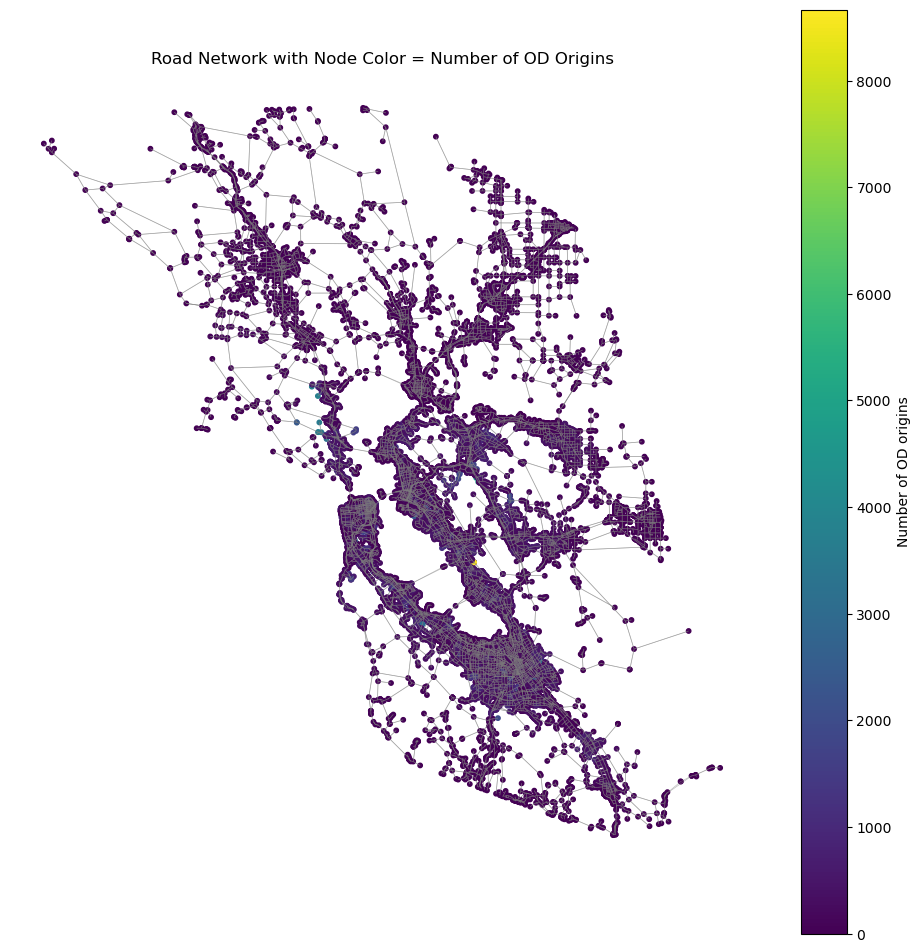

In [8]:
plot_network_with_origin_counts(nodes, edges, df_OD.to_pandas())

In [7]:
def check_all_od_in_nodes(nodes, df_OD, column_origin, column_destination, column_nodes):
    node_ids = set(nodes[column_nodes])
    origins = set(df_OD[column_origin])
    destinations = set(df_OD[column_destination])

    missing_origins = origins - node_ids
    missing_destinations = destinations - node_ids

    print(f"Origins missing from nodes: {missing_origins}")
    print(f"Destinations missing from nodes: {missing_destinations}")

    if not missing_origins and not missing_destinations:
        print("All origins and destinations are present in node_ids.")
    else:
        print("Some origins or destinations are missing from node_ids.")
    return missing_origins,missing_destinations
column_nodes = "osmid"
column_origin = "origin_osmid"
column_destination = "destination_osmid"

# Example usage:
missing_origins, missing_destinations = check_all_od_in_nodes(nodes, df_OD, column_origin, column_destination, column_nodes)
print("missing origins: ",len(missing_origins), " missing destinations: ",len(missing_destinations))
from concurrent.futures import ThreadPoolExecutor, as_completed
from typing import Dict, List, Tuple
import pandas as pd

def check_OD_2_grid_parallel(
    grid2OD: Dict[int, List[int]],
    nodes: pd.DataFrame,
    column_osmid_node: str,
    max_workers: int = None
) -> Tuple[int, List[int]]:
    
    # Convert node column to a set for fast lookup
    valid_osmids = set(nodes[column_osmid_node].values)

    # Function to process a single grid cell
    def process_grid_cell( osmids_in_cell):
        missing = [osmid for osmid in osmids_in_cell if osmid in valid_osmids]
        return len(missing), missing

    results = []
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = [executor.submit(process_grid_cell, osmids)
                   for _, osmids in grid2OD.items()]
        
        for future in as_completed(futures):
            results.append(future.result())

    # Aggregate results
    total_count = sum(r[0] for r in results)
    missing_list = [osmid for r in results for osmid in r[1]]
    return total_count, missing_list


count, missing = check_OD_2_grid_parallel(
    grid2OD=grid2OD,
    nodes=nodes,
    column_osmid_node='osmid',
    max_workers=4  # Or use None to use all available threads
)
print("Count of matching ODs:", count)



Origins missing from nodes: set()
Destinations missing from nodes: set()
All origins and destinations are present in node_ids.
missing origins:  0  missing destinations:  0
Count of matching ODs: 34063


In [16]:
import numpy as np
import networkx as nx

def box_counting_dimension(G, box_sizes=None):
    """
    Estimate the fractal (box-counting) dimension of a network G.
    Uses shortest-path distances between nodes.
    """
    if box_sizes is None:
        # Use a range of box sizes based on the network diameter
        diameter = nx.diameter(G)
        box_sizes = np.unique(np.logspace(0, np.log10(diameter), num=10, dtype=int))
        box_sizes = box_sizes[box_sizes > 0]

    N_boxes = []
    for size in box_sizes:
        covered = set()
        boxes = 0
        nodes = set(G.nodes())
        while nodes:
            # Pick a random node as box center
            center = nodes.pop()
            # Find all nodes within 'size' hops
            neighbors = nx.single_source_shortest_path_length(G, center, cutoff=size).keys()
            covered.update(neighbors)
            nodes -= set(neighbors)
            boxes += 1
        N_boxes.append(boxes)

    # Fit log(N_boxes) vs log(1/box_size)
    coeffs = np.polyfit(np.log(1/box_sizes), np.log(N_boxes), 1)
    fractal_dim = coeffs[0]
    return fractal_dim, box_sizes, N_boxes

# Example usage:
D, sizes, counts = box_counting_dimension(G)
print(f"Estimated fractal dimension: {D:.2f}")

Estimated fractal dimension: 1.94


In [ ]:
import networkit as nk
import numpy as np
from concurrent.futures import ProcessPoolExecutor
from tqdm import tqdm
import matplotlib.pyplot as plt
import psutil
import time
import threading

# Monitoring
def monitor_resources(interval=5):
    process = psutil.Process()
    while True:
        cpu = process.cpu_percent(interval=0.1)
        mem = process.memory_info().rss / 1e6
        print(f"[Monitor] CPU: {cpu:.1f}% | Mem: {mem:.1f} MB")
        time.sleep(interval)

# --- Use NetworKit's fast BFS
def compute_fractal_dimension_nk(G_nk, node, radii):
    bfs = nk.distance.BFS(G_nk, source=node, storePaths=False)
    bfs.run()
    counts = [(r, bfs.numberOfNodesAtDistance(r)) for r in radii if bfs.numberOfNodesAtDistance(r) > 0]

    filtered = [(r, c) for r, c in counts if c > 1]
    if len(filtered) < 2:
        return node, 0.0

    log_r = np.log([r for r, _ in filtered])
    log_N = np.log([c for _, c in filtered])
    d, _ = np.polyfit(log_r, log_N, 1)
    return node, d

# Wrapper for parallelism
# Top-level helper to make the function picklable
def compute_fractal_dimension_wrapper(args):
    G_nk, node, radii = args
    return compute_fractal_dimension_nk(G_nk, node, radii)

def compute_all_fractal_dimensions_nk(G_nk, radii, max_workers=None):
    nodes = list(range(G_nk.numberOfNodes()))
    args = [(G_nk, node, radii) for node in nodes]
    with ProcessPoolExecutor(max_workers=max_workers) as executor:
        results = executor.map(compute_fractal_dimension_wrapper, args)
        results = list(tqdm(results, total=len(nodes), desc="Fractal dim (NetworKit)"))
    return dict(results)


# Convert from NetworkX
def from_networkx_to_networkit(G_nx):
    G_nk = nk.Graph(n=G_nx.number_of_nodes(), weighted=False, directed=False)
    id_map = {node: i for i, node in enumerate(G_nx.nodes())}
    for u, v in G_nx.edges():
        G_nk.addEdge(id_map[u], id_map[v])
    return G_nk, id_map

# --- Example usage ---
import networkx as nx

G_nk, id_map = from_networkx_to_networkit(G)
# exact
t_start_diam = time.time()
def exact_diameter_bfs(G):
    max_dist = 0
    for u in range(G.numberOfNodes()):
        bfs = nk.distance.BFS(G, u, storePaths=False)
        bfs.run()
        local_max = bfs.distance(u)  # sometimes 0
        for v in range(G.numberOfNodes()):
            d = bfs.distance(v)
            if d != float('inf'):
                max_dist = max(max_dist, d)
    return int(max_dist)

# Usage
diameter = exact_diameter_bfs(G_nk)
t_end_diam = time.time()
print("diameter estimate computed in: ",t_start_diam - t_end_diam, " with value: ",diameter)
radii = np.arange(1, diameter - 1)

# Monitor system
monitor_thread = threading.Thread(target=monitor_resources, daemon=True)
monitor_thread.start()

# Compute
fractal_dims = compute_all_fractal_dimensions_nk(G_nk, radii, max_workers=None)

# Map results back to networkx
inv_id_map = {v: k for k, v in id_map.items()}
for nk_id, d in fractal_dims.items():
    G.nodes[inv_id_map[nk_id]]['fractal_dimension'] = d

# Visualize
feature_vector = [G.nodes[n].get("fractal_dimension", 0) for n in G.nodes()]
plt.hist(feature_vector, bins=30)
plt.title("Fractal dimension distribution (NetworKit)")
plt.xlabel("d")
plt.ylabel("count")
plt.show()


NameError: name 'd' is not defined

In [ ]:
print("diameter estimate computed in: ",t_start_diam - t_end_diam, " with value: ",diameter)
radii = np.arange(1, diameter - 1)

# Monitor system
monitor_thread = threading.Thread(target=monitor_resources, daemon=True)
monitor_thread.start()

# Compute
fractal_dims = compute_all_fractal_dimensions_nk(G_nk, radii, max_workers=None)

# Map results back to networkx
inv_id_map = {v: k for k, v in id_map.items()}
for nk_id, d in fractal_dims.items():
    G.nodes[inv_id_map[nk_id]]['fractal_dimension'] = d

# Visualize
feature_vector = [G.nodes[n].get("fractal_dimension", 0) for n in G.nodes()]
plt.hist(feature_vector, bins=30)
plt.title("Fractal dimension distribution (NetworKit)")
plt.xlabel("d")
plt.ylabel("count")
plt.show()
